In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [3]:
TRAIN_PATH = Path("../data/processed/train_data.csv")
TEST_PATH = Path("../data/processed/test_data.csv")

train_data = pd.read_csv(TRAIN_PATH)
test_data = pd.read_csv(TEST_PATH)

print("Training shape:", train_data.shape)
print("Testing shape:", test_data.shape)

display(train_data.head())

Training shape: (1600, 21)
Testing shape: (400, 21)


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
2,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
3,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1
4,1859,0,0.5,1,3,0,22,0.7,164,1,...,1004,1654,1067,17,1,10,1,0,0,1


In [5]:
print("Missing values in training data:")
display(train_data.isnull().sum().sum())

print("Duplicate rows in training data:")
display(train_data.duplicated().sum())

print("Data types:")
display(train_data.dtypes)

Missing values in training data:


0

Duplicate rows in training data:


0

Data types:


battery_power      int64
blue               int64
clock_speed      float64
dual_sim           int64
fc                 int64
four_g             int64
int_memory         int64
m_dep            float64
mobile_wt          int64
n_cores            int64
pc                 int64
px_height          int64
px_width           int64
ram                int64
sc_h               int64
sc_w               int64
talk_time          int64
three_g            int64
touch_screen       int64
wifi               int64
price_range        int64
dtype: object

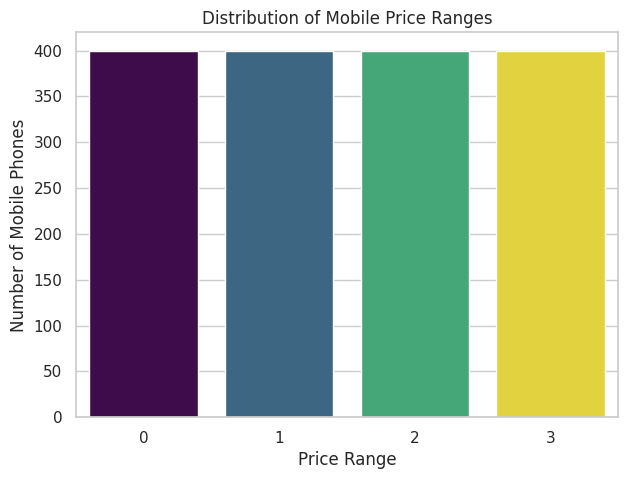

In [7]:
target_counts = train_data["price_range"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
sns.barplot(
    x=target_counts.index,
    y=target_counts.values,
    hue=target_counts.index,
    palette="viridis",
    legend=False
)

plt.title("Distribution of Mobile Price Ranges")
plt.xlabel("Price Range")
plt.ylabel("Number of Mobile Phones")
plt.show()

In [9]:
feature_columns = train_data.drop(columns=["price_range"]).columns

display(train_data[feature_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
battery_power,1600.0,1236.665625,438.041695,502.0,849.50,1222.5,1614.000,1998.0
blue,1600.0,0.494375,0.500125,0.0,0.00,0.0,1.000,1.0
clock_speed,1600.0,1.529313,0.817696,0.5,0.70,1.5,2.225,3.0
dual_sim,1600.0,0.506875,0.500109,0.0,0.00,1.0,1.000,1.0
fc,1600.0,4.322500,4.337799,0.0,1.00,3.0,7.000,19.0
four_g,1600.0,0.518125,0.499828,0.0,0.00,1.0,1.000,1.0
int_memory,1600.0,32.063125,18.264382,2.0,16.00,31.5,48.000,64.0
m_dep,1600.0,0.503562,0.289000,0.1,0.20,0.5,0.800,1.0
mobile_wt,1600.0,140.102500,35.283567,80.0,109.00,141.0,170.000,200.0
n_cores,1600.0,4.546875,2.286607,1.0,3.00,5.0,7.000,8.0


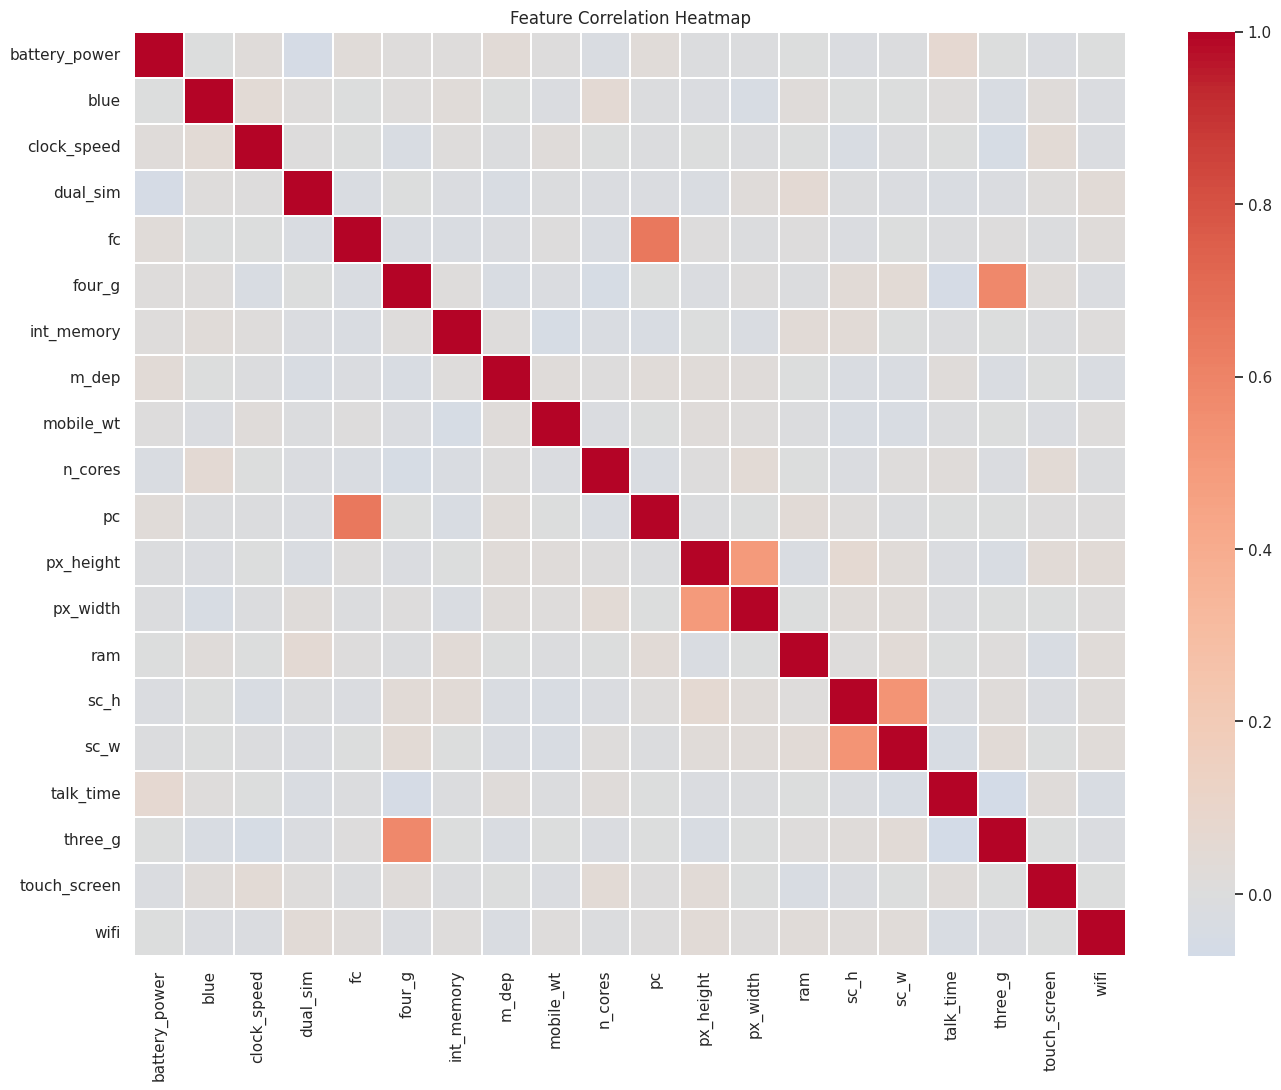

In [11]:
plt.figure(figsize=(16, 12))

correlation_matrix = train_data[feature_columns].corr()

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.2
)

plt.title("Feature Correlation Heatmap")
plt.show()

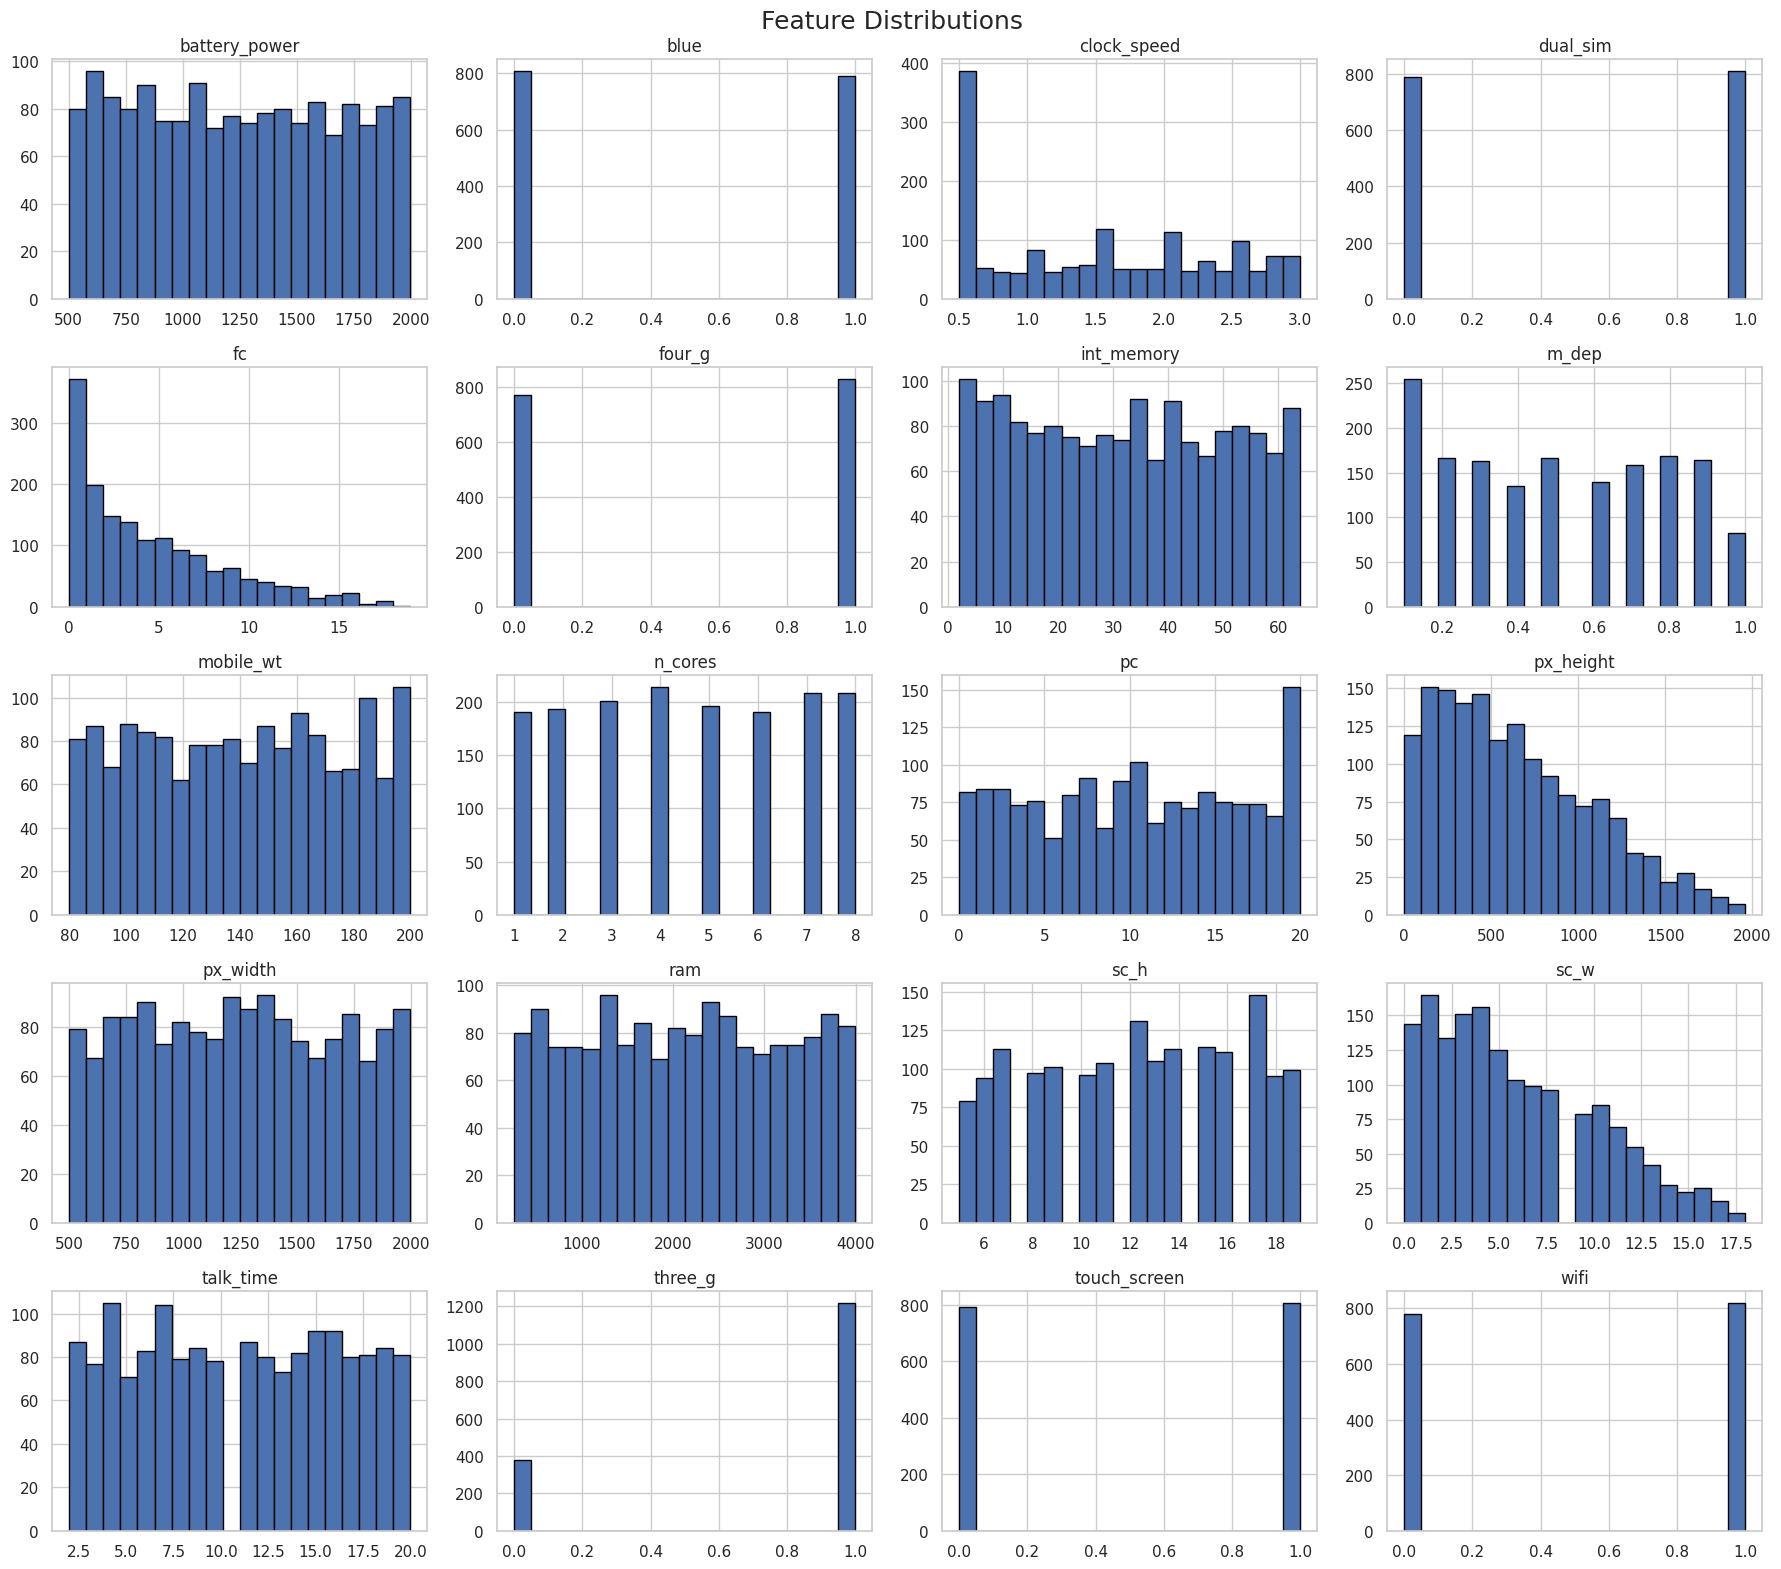

In [13]:
train_data[feature_columns].hist(
    figsize=(18, 16),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Feature Distributions", fontsize=18)
plt.tight_layout()
plt.show()

In [15]:
X_train = train_data.drop(columns=["price_range"])
y_train = train_data["price_range"]

X_test = test_data.drop(columns=["price_range"])
y_test = test_data["price_range"]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (1600, 20)
y_train: (1600,)
X_test: (400, 20)
y_test: (400,)
